<a href="https://colab.research.google.com/github/Ayiekooo/SemProject_MLEngine/blob/main/Model_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import files
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset (1).csv


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv('diabetes_prediction_dataset.csv')

# 2. Quick check for missing values or duplicates
print("Missing values:", df.isnull().sum().sum())
df = df.drop_duplicates()
print("Dataset size after cleaning:", df.shape)

Missing values: 0
Dataset size after cleaning: (96146, 9)


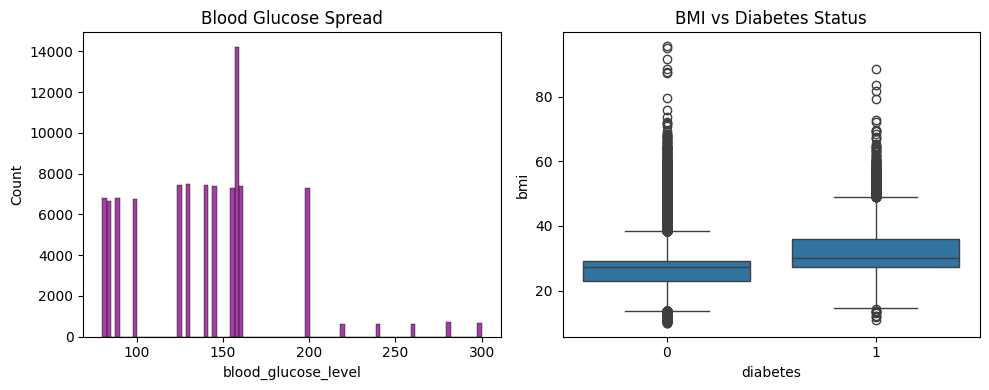

In [7]:
# Simple charts for our Exploratory Data Analysis
plt.figure(figsize=(10, 4))

# Chart 1: Blood Glucose distribution
plt.subplot(1, 2, 1)
sns.histplot(df['blood_glucose_level'], color='purple')
plt.title('Blood Glucose Spread')

# Chart 2: BMI boxplot
plt.subplot(1, 2, 2)
sns.boxplot(x='diabetes', y='bmi', data=df)
plt.title('BMI vs Diabetes Status')

plt.tight_layout()
plt.show()

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Prepare our inputs (X) and target answer (y)
# We convert text columns like gender into numbers automatically
X = pd.get_dummies(df.drop(columns=['diabetes']), drop_first=True)
y = df['diabetes']

# Set up our base model
model = RandomForestClassifier(random_state=42)

# Test the model using 5-Fold Cross Validation
scores = cross_val_score(model, X, y, cv=5)

print("Accuracy scores for each test round:", scores)
print("Average Accuracy:", scores.mean())

Accuracy scores for each test round: [0.96900676 0.96947319 0.96656092 0.96910916 0.96905715]
Average Accuracy: 0.9686414373419285


## Task 4: Comparing Different Machine Learning Models

In this section, we compare the Random Forest model with Logistic Regression and Support Vector Machine (SVM). We use five-fold stratified cross-validation to evaluate the models using accuracy, precision, recall, F1-score and ROC-AUC.

In [10]:
# Task 4: Comparing different machine learning models

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Define the cross-validation method
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Create the models we want to compare
models = {
    "Random Forest": RandomForestClassifier(random_state=42),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced")
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        LinearSVC(class_weight="balanced", random_state=42)
    )
}

# Choose the measures to evaluate the models
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

# Store the results
results = []

# Test each model using the same cross-validation method
for name, model in models.items():

    print("Testing", name)

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

# Display the final comparison
results_df = pd.DataFrame(results)

display(results_df.round(4))

Testing Random Forest
Testing Logistic Regression
Testing SVM


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.9686,0.9454,0.6832,0.7932,0.9611
1,Logistic Regression,0.8863,0.4298,0.8808,0.5777,0.9619
2,SVM,0.8869,0.4312,0.8819,0.5791,0.9619


### Interpretation of Model Comparison Results

The three models were evaluated using five-fold stratified cross-validation. Random Forest achieved the highest accuracy of 96.86%, precision of 94.54% and F1-score of 79.32%. This shows that it provided the best balance between correctly identifying diabetes-positive cases and avoiding false-positive predictions.

Logistic Regression achieved a recall of 88.08%, while SVM achieved 88.19%. These models identified a higher proportion of positive cases than Random Forest, but their precision and F1-scores were lower. Both models also achieved a ROC-AUC of 0.9619, slightly higher than the Random Forest score of 0.9611.

Overall, Random Forest performed best based on accuracy, precision and F1-score, while SVM achieved the highest recall. The results show that different algorithms have different strengths. Further testing would be necessary before selecting a model for real clinical use.